<!-- DRAFT: Graeme to edit -->
# Day 2 · 05b (full data) — Lab: teaching price response with synthetic discounts (15 min)

05's price response is learnt from the discounts the shop actually ran. Those are few, short
and bunched in the same series. Here we try a research idea from phase 7: **plant extra
one-week price cuts** in the oversampled training copies, each with a known lift, and see
whether the model learns from them. This is **experimental**: the research tried it but never
accepted it (`docs/gfm_learnings.md` §5, [100k set]).

| | |
|---|---|
| Starts from | the selected 05 model |
| Adds | two one-week cuts per oversampled copy, 10–30% deep, with a planted lift |
| Originals | untouched: only the copies get synthetic weeks |
| Measured | the same sweep and probes as 04/05, plus an **echo check** |
| Decides | whether 06–10 use 05 or 05b, by a rule written before the results |

Goals

1. Build 05's training data with and without synthetic cuts, and see what was planted.
2. Choose between 05 and 05b by a rule on the validation window (3 seeds each).
3. Fit 05's model on the synthetic data (3 seeds) and score the test window once.
4. Check whether the model gives back the lift we planted.

**In the chain:** reads `05_selected`, `04_price`, `02_shortlist` and `00_baselines`, writes
`05b_synthetic`. Its `use` key tells `gd.selected_config()` whether 06–10 build on 05 or 05b.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## Intuition: worked examples with the answer written in

![Ask the model 'what if?'](../slides/img/response_sketch.png)

A model learns price response from weeks where the price moved. If the shop rarely cuts prices
outside a few promotions, there is little to learn from. Synthetic cuts are worked examples in
a textbook. In a copy of a series we lower the price for one week and raise its sales by a lift
we choose. If the model learnt from them, a probe with the same cut should **echo** back
roughly that lift. The risk is that it learns our made-up rule rather than the shop's
customers, so we check accuracy on real test weeks too.

<!-- DRAFT: Graeme to edit -->
## 1. From 05's config to 05b's

05b is 05's config plus one key, `synthetic`. The cuts are planted with **one fixed random
seed** for all three training seeds. So the fits see the same data, and their spread is
training noise only, as in 05.

In [2]:
baselines_cfg = gd.load_config("00_baselines")
noise_floor = gd.load_config("02_shortlist")["noise_floor"]
price_cfg = gd.load_config("04_price")
cfg_a = gd.load_config("05_selected")
price_channel = price_cfg.get("price_channel", "price_index")
examples = baselines_cfg["examples"]
example_ids = gplt.example_ids(examples)

cfg_b = dict(cfg_a)
oversample_added = not cfg_a.get("oversample")
if oversample_added:      # synthetic cuts live in the copies, so they need oversampling
    cfg_b["oversample"] = price_cfg.get("oversample") or {
        "rule": "rolling", "cap": gp.COPY_CAP, "multiplier": gp.COPY_MULTIPLIER}
    print("05 has no oversampling: 05b adds 04's default, so it differs from 05 in two ways.")
cfg_b["synthetic"] = {"cuts_per_copy": 2}
synthetic_seed = bc.RANDOM_SEED

raw = gd.train_panel()
panel, train, test, data_a = gp.prepare(cfg_a, panel=raw)
_, _, _, data_b = gp.prepare(cfg_b, panel=raw, synthetic_seed=synthetic_seed)
info = gplt.series_table(panel)
report_ids = gp.report_ids(train)

params = cfg_a["params"]
max_steps = cfg_a["max_steps"]
if oversample_added:
    max_steps = gd.scaled_max_steps(data_b.fit_df["unique_id"].nunique(),
                                    batch_size=params.get("batch_size", 256))
print(f"{data_b.fit_df['unique_id'].nunique():,} training series incl. copies | "
      f"{max_steps:,} steps | {len(report_ids):,} report series | seeds {gd.SEEDS}")
pd.Series({"oversample": cfg_b["oversample"], "synthetic": cfg_b["synthetic"],
           "synthetic_seed": synthetic_seed, "price_channel": price_channel})

40,079 training series incl. copies | 11,718 steps | 680 report series | seeds [46335, 11207, 90218]


oversample        {'rule': 'rolling', 'cap': 15, 'multiplier': 5}
synthetic                                    {'cuts_per_copy': 2}
synthetic_seed                                              46335
price_channel                                         price_index
dtype: object

<!-- DRAFT: Graeme to edit -->
### What was planted

Each copy is its original series with a few weeks changed. Comparing them row by row finds
the planted weeks: lower price, higher units. The table counts them by depth, with the lift
we asked for and the lift that landed (units are whole numbers, so small sellers round).

The planted lifts imply an elasticity of roughly −3 to −5 (lift ÷ cut: +60% for a 20% cut is
−3). That is close to the ≈ −3.6 measured on this data (`docs/progress.md`), and far stronger
than the research's −0.4 to −0.7 [100k set]. This panel's price variation is mostly short
promo cuts with big short-term lifts.

In [3]:
def planted_weeks(fit_df: pd.DataFrame, y_shift: float) -> pd.DataFrame:
    """Weeks where a copy's price differs from its original series': depth and lift."""
    is_copy = fit_df["unique_id"].str.contains(gp.COPY_TAG, regex=False)
    copies = fit_df[is_copy].copy()
    copies["original"] = copies["unique_id"].str.split(gp.COPY_TAG).str[0]
    originals = fit_df[~is_copy].rename(columns={"unique_id": "original"})
    both = copies.merge(originals, on=["original", "ds"], suffixes=("_b", "_a"))
    both = both[~np.isclose(both["price_index_a"], both["price_index_b"])].copy()
    both["depth"] = (1 - both["price_index_b"] / both["price_index_a"]).round(2)
    units_a = both["y_a"] - y_shift
    both["lift"] = (both["y_b"] - y_shift) / units_a.where(units_a > 0) - 1
    return both[["unique_id", "ds", "depth", "lift"]]


planted = planted_weeks(data_b.fit_df, data_b.y_shift)
planted_table = planted.groupby("depth").agg(weeks=("lift", "size"),
                                             median_lift_landed=("lift", "median"))
planted_table["lift_asked"] = planted_table.index.map(gp.SYNTHETIC_LIFT)
print(f"{len(planted):,} planted weeks in {planted['unique_id'].nunique():,} copies")
planted_table.round(2)

44,666 planted weeks in 22,423 copies


,weeks,median_lift_landed,lift_asked
depth,,,
0.10,8966,0.35,0.35
0.15,8869,0.45,0.45
0.20,8986,0.60,0.60
0.25,8905,1.00,1.00
0.30,8940,1.50,1.50


<!-- DRAFT: Graeme to edit -->
## 2. The rule, written before the results

Notebooks 06–10 use 05b **only if all three hold**; otherwise they keep 05. Every check reads
the **validation window**: 05's config and 05b's are each fitted with 3 seeds on the weeks
before `VALID_START`, and swept and probed on that window's report series.

1. 05b's median arc elasticity at ±20% (`median_e20`, seed-mean sweep) is **more negative**
   than 05's;
2. its share of right-signed series under the **sustained** probes (averaged over the four
   shocks) is **higher** than 05's;
3. its median validation RMSSE is no more than the 02 noise floor above 05's.

The first two ask for a stronger, more consistent price response. The third says it must not
cost real accuracy. The test window is scored once afterwards, as the reported outcome.

<!-- DRAFT: Graeme to edit -->
## 3. Choosing on the validation window

Both configs are rebuilt with `cutoff=bc.VALID_START`, so the reference price, the copies and
the planted cuts all come from the weeks before it. Each is fitted with the same 3 seeds.

In [4]:
_, inner_train, valid, valid_a = gp.prepare(cfg_a, panel=raw, cutoff=bc.VALID_START)
valid_b = gp.prepare(cfg_b, panel=raw, synthetic_seed=synthetic_seed,
                     cutoff=bc.VALID_START)[3]
valid_report_ids = gp.report_ids(inner_train)
max_steps_a = cfg_a["max_steps"]
print(f"validation: {valid_b.fit_df['unique_id'].nunique():,} training series incl. copies | "
      f"{len(valid_report_ids):,} report series")


def valid_extras(nf, data):
    """Sweep and probes on the validation window, computed while the model is in memory."""
    return {"sweep": gp.price_sweep(nf, data, valid_report_ids, channel=price_channel),
            "probe": gp.probe(nf, data, valid_report_ids, channel=price_channel)}


def model_05_valid(seed):
    return gd.build_nbeatsx(params, valid_a, max_steps_a, seed, "GFM_selected")


def model_05b_valid(seed):
    return gd.build_nbeatsx(params, valid_b, max_steps, seed, "GFM_synthetic")


with bc.Timer() as t:
    valid_runs = {"05": gd.fit_seeds(model_05_valid, valid_a, "05b_valid_05",
                                     extras=valid_extras),
                  "05b": gd.fit_seeds(model_05b_valid, valid_b, "05b_valid_05b",
                                      extras=valid_extras)}
if gd.TRAIN:
    print(f"validation fits: {t.seconds / 60:.1f} min")

validation: 38,251 training series incl. copies | 680 report series


2026-11-24 16:12:55,979	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-11-24 16:12:56,148	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


In [5]:
def seed_mean(frames: list[pd.DataFrame], keys: list[str]) -> pd.DataFrame:
    """Average the numeric columns of per-seed frames that share ``keys``."""
    return pd.concat(frames).groupby(keys, as_index=False).mean(numeric_only=True)


def right_sign_share(summary: pd.DataFrame) -> float:
    """Mean share of right-signed series over the sustained probes."""
    return float(summary[summary["mode"] == "sustained"]["share_right_sign"].mean())


valid_numbers = {}
for name, runs in valid_runs.items():
    sweep = gp.seed_mean_sweep(runs)
    probe = seed_mean([r["probe"] for r in runs], ["unique_id", "shock", "mode"])
    fcst = gd.seed_forecasts(runs)
    mean_col = [c for c in fcst.columns if c.endswith("_mean")][0]
    rmsse = gd.per_series(gd.score(fcst[["unique_id", "ds", mean_col]], valid, inner_train))
    report = gp.elasticity_report(gp.arc_elasticity(sweep))
    valid_numbers[name] = {"median_e20": report["median_e20"],
                           "share_right_sign": right_sign_share(gp.probe_summary(probe)),
                           "median_rmsse": float(rmsse[mean_col].median())}
valid_numbers = pd.DataFrame(valid_numbers).T

checks = {
    "stronger response (median_e20 more negative)":
        valid_numbers.loc["05b", "median_e20"] < valid_numbers.loc["05", "median_e20"],
    "more right-signed series (sustained probes)":
        valid_numbers.loc["05b", "share_right_sign"] > valid_numbers.loc["05", "share_right_sign"],
    "accuracy within the noise floor":
        valid_numbers.loc["05b", "median_rmsse"] - valid_numbers.loc["05", "median_rmsse"]
        <= noise_floor,
}
use = "05b" if all(checks.values()) else "05"
print(f"later notebooks use: {use}")
valid_numbers.round(4)

later notebooks use: 05


,median_e20,share_right_sign,median_rmsse
05,-1.3693,0.9809,0.5825
05b,-1.4059,0.9798,0.5864


In [6]:
pd.Series(checks)

stronger response (median_e20 more negative)     True
more right-signed series (sustained probes)     False
accuracy within the noise floor                  True
dtype: bool

<!-- DRAFT: Graeme to edit -->
## 4. Fit 05's model on the synthetic data, all training weeks (3 seeds)

The choice is made; these fits are the reported result. While each model is in memory, we
run the single-channel sweep and the probes on the report series, and the price scenarios
on the example series. Only the first seed is saved, for later notebooks.

In [7]:
def price_extras(nf, data):
    """Sweep, probes and example scenarios, computed while the model is in memory."""
    return {"sweep": gp.price_sweep(nf, data, report_ids, channel=price_channel),
            "probe": gp.probe(nf, data, report_ids, channel=price_channel),
            "scenarios": gp.scenario_forecasts(nf, data, example_ids, channel=price_channel)}


def synthetic_model(seed):
    return gd.build_nbeatsx(params, data_b, max_steps, seed, "GFM_synthetic")


run_name = "05b_synthetic"
runs = [gd.fit_seed(synthetic_model, gd.SEEDS[0], data_b, run_name, extras=price_extras,
                    save_as="05b_synthetic")]
runs += gd.fit_seeds(synthetic_model, data_b, run_name, seeds=gd.SEEDS[1:], extras=price_extras)
health_cols = ["seed", "fit_seconds", "oscillation", "best_frac", "final_over_best", "neg_share"]
gd.summaries(runs)[health_cols].round(3)

,seed,fit_seconds,oscillation,best_frac,final_over_best,neg_share
0,46335,389.7,0.014,0.872,1.022,0.031
1,11207,371.4,0.024,0.698,1.033,0.021
2,90218,367.7,0.015,0.822,1.046,0.026


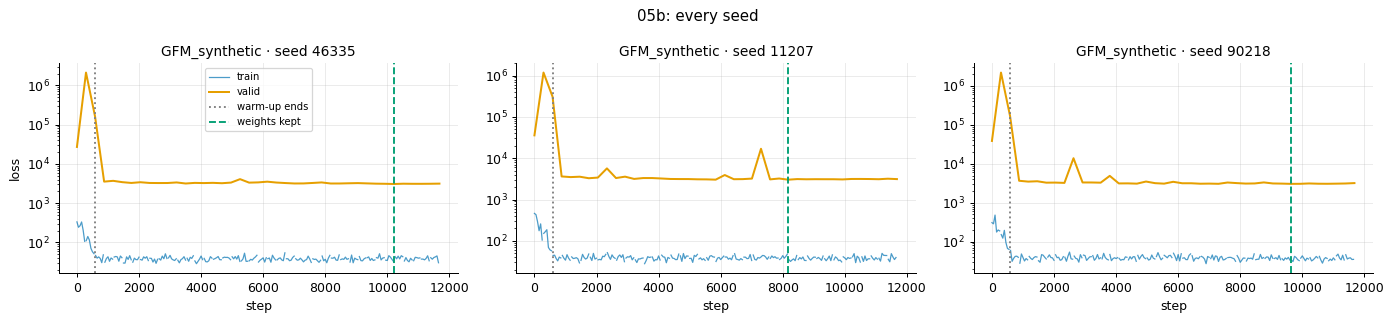

In [8]:
gplt.plot_training(runs, warmup=gd.warmup_steps(max_steps), title="05b: every seed")

<!-- DRAFT: Graeme to edit -->
### 05's reference numbers

The same sweep and probes on the test window, on 05's saved model (one seed). They are
computed here, so this notebook does not depend on how 05 stored its runs. Against 05b's
3-seed mean this is not quite like for like, which is why the choice was made on validation,
with 3 seeds of each.

In [9]:
def reference_sweep() -> pd.DataFrame:
    return gp.price_sweep(gd.load_model(cfg_a["saved_model"]), data_a, report_ids,
                          channel=price_channel)


def reference_probe() -> pd.DataFrame:
    return gp.probe(gd.load_model(cfg_a["saved_model"]), data_a, report_ids,
                    channel=price_channel)


sweep_a = gd.cached("05b_reference_sweep", reference_sweep)
probe_a = gd.cached("05b_reference_probe", reference_probe)

<!-- DRAFT: Graeme to edit -->
For 05b, each series' sweep and probe are averaged over the three seeds first, then
summarised: the response of the seed-mean model. The per-seed table shows the spread. The
research found each run tends to be all-negative or all-positive in its response (§6), so
watch for one seed that disagrees with the others.

In [10]:
sweep_b = seed_mean([r["sweep"] for r in runs], ["unique_id", "shift"])
probe_b = seed_mean([r["probe"] for r in runs], ["unique_id", "shock", "mode"])
el_a = gp.arc_elasticity(sweep_a)
el_b = gp.arc_elasticity(sweep_b)

per_seed = []
for r in runs:
    report = gp.elasticity_report(gp.arc_elasticity(r["sweep"]))
    per_seed.append({"seed": r["summary"]["seed"], **report})
per_seed = pd.DataFrame(per_seed)
reports = pd.DataFrame({"05 selected": gp.elasticity_report(el_a),
                        "05b synthetic": gp.elasticity_report(el_b)}).T
per_seed[["seed", "median_e20", "share_perverse", "share_flat"]].round(3)

,seed,median_e20,share_perverse,share_flat
0,46335,-1.282,0.015,0.010
1,11207,-1.511,0.004,0.009
2,90218,-1.369,0.009,0.003


In [11]:
reports.round(3)

,n,n_estimable,median_e20,share_perverse,share_flat,invariance,median_e5,median_e10
05 selected,680.0,680.0,-1.344,0.013,0.007,1.132,-1.522,-1.484
05b synthetic,680.0,680.0,-1.429,0.006,0.004,1.140,-1.629,-1.575


<!-- DRAFT: Graeme to edit -->
## 5. The echo check: does the model give back the planted lift?

A one-week **pulse** probe is the same experiment as a planted cut: the price falls for one
week and nothing else changes. We compare the lift planted at 10%, 20% and 30% with the
median lift each model predicts in the pulse week.

In the chart, the x-axis is the size of the one-week cut and the y-axis the median lift in
that week. The black dashed line is what we planted; the coloured lines are what 05 and 05b
give back.

In [12]:
summary_a = gp.probe_summary(probe_a)
summary_b = gp.probe_summary(probe_b)

echo_rows = []
for depth in (0.10, 0.20, 0.30):
    row = {"depth": depth, "planted": gp.SYNTHETIC_LIFT[depth]}
    for name, summ in (("05", summary_a), ("05b", summary_b)):
        for mode in ("pulse", "sustained"):
            hit = summ[(summ["mode"] == mode) & np.isclose(summ["shock"], -depth)]
            row[f"{name} {mode}"] = float(hit["median_lift"].iloc[0])
    echo_rows.append(row)
echo = pd.DataFrame(echo_rows).set_index("depth")
echo.round(3)

,planted,05 pulse,05 sustained,05b pulse,05b sustained
depth,,,,,
0.1,0.35,0.142,0.167,0.160,0.193
0.2,0.60,0.280,0.351,0.309,0.407
0.3,1.50,0.412,0.527,0.452,0.608


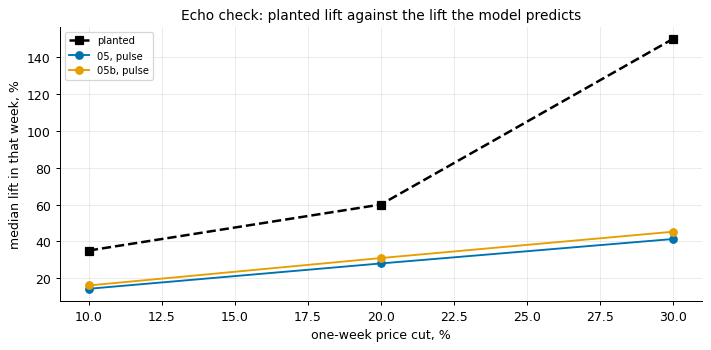

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
x = echo.index * 100
ax.plot(x, echo["planted"] * 100, "s--", color="black", lw=2, label="planted")
ax.plot(x, echo["05 pulse"] * 100, "o-", color=gplt.MODEL_COLOURS[0], label="05, pulse")
ax.plot(x, echo["05b pulse"] * 100, "o-", color=gplt.MODEL_COLOURS[1], label="05b, pulse")
ax.set(xlabel="one-week price cut, %", ylabel="median lift in that week, %",
       title="Echo check: planted lift against the lift the model predicts")
ax.legend()
fig.tight_layout()
plt.show()

<!-- DRAFT: Graeme to edit -->
### Reading the result

* The planted line is the answer we wrote in. 05 never saw it; 05b saw it in about 2 weeks
  per copy.
* If 05b's line sits near the planted one, the model learnt the rule. That shows it *can*
  learn a price response from data like this, not that the shop's customers behave so.
* The probe moves only the price channel. A planted cut also changed the discount depth, so
  a partial echo is expected. At a 20% cut, look for 05b's lift moving from 05's ≈ +35%
  towards the planted +60%. Here it reaches ≈ +41% (sustained cut).

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 6. Probes: sustained against pulse (F11)

The probes are the research's phase 7 price shocks: −10%, −20%, −30% and +20%, applied to
every test week (**sustained**) or to one week only (**pulse**). Each chart has two panels:

* **left, lift:** median change in units against the shock. A cut should lift sales, so the
  points should sit above zero for the cuts and below zero for the +20% rise.
* **right, spill:** for the pulse only, the median change in the weeks that were *not*
  shocked. Ideally about zero. A large spill means the model smears one week's price across
  the horizon.

The research's pass bar was a median elasticity of −0.3 or stronger, with the right sign
(§5). On this data, with an empirical ≈ −3.6, a model can pass that bar and still be far
weaker than the shop's customers.

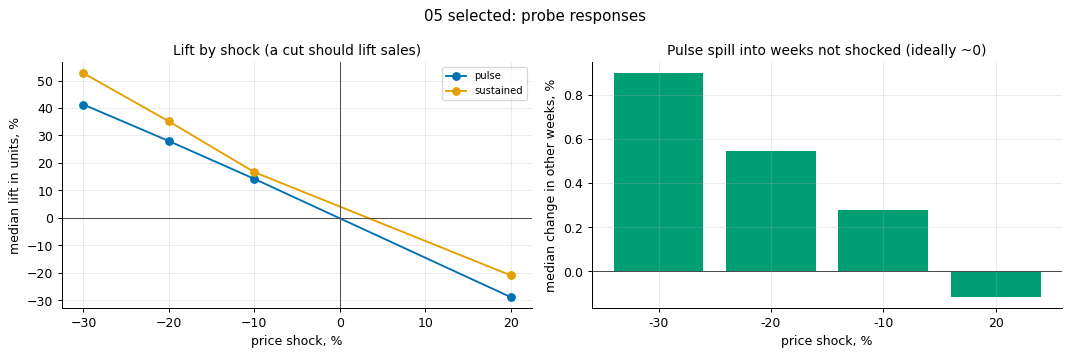

In [14]:
gplt.plot_probe(summary_a, title="05 selected: probe responses")

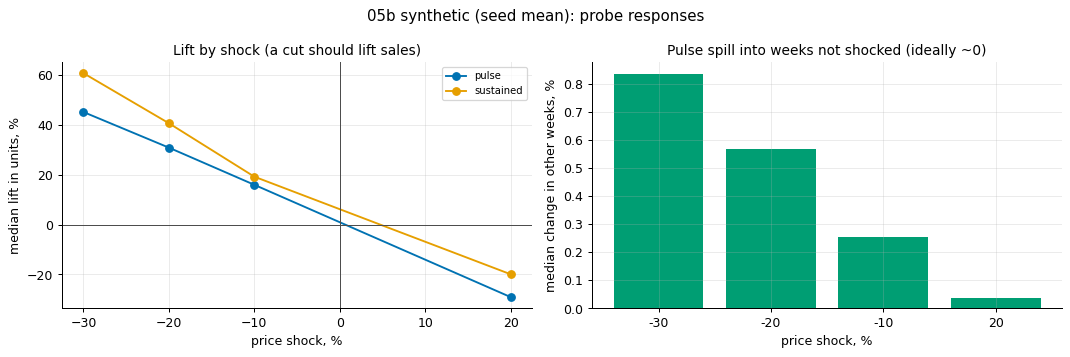

In [15]:
gplt.plot_probe(summary_b, title="05b synthetic (seed mean): probe responses")

<!-- DRAFT: Graeme to edit -->
## 7. Price response by strength and class (F6, F7)

The same charts as 04 and 05, now with 05 and 05b side by side:

* **strength (F6):** one bar per model, split into the share of series that are highly
  elastic (≤ −3), elastic, inelastic, flat (|e| < 0.05) or perverse (e > 0);
* **by class (F7):** median elasticity per sales class A–I, with the empirical values dashed.
  More negative is a stronger response; below the dotted zero line is the right sign.

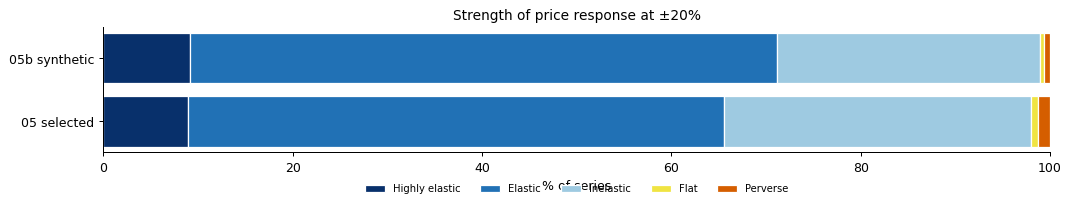

e_arc,Highly elastic,Elastic,Inelastic,Flat,Perverse
05 selected,9.0,56.6,32.4,0.7,1.3
05b synthetic,9.1,62.1,27.8,0.4,0.6


In [16]:
empirical = gp.empirical_elasticity(train, report_ids)
strength = {"05 selected": gp.e20(el_a), "05b synthetic": gp.e20(el_b)}
gplt.plot_elasticity_strength(strength, title="Strength of price response at ±20%")

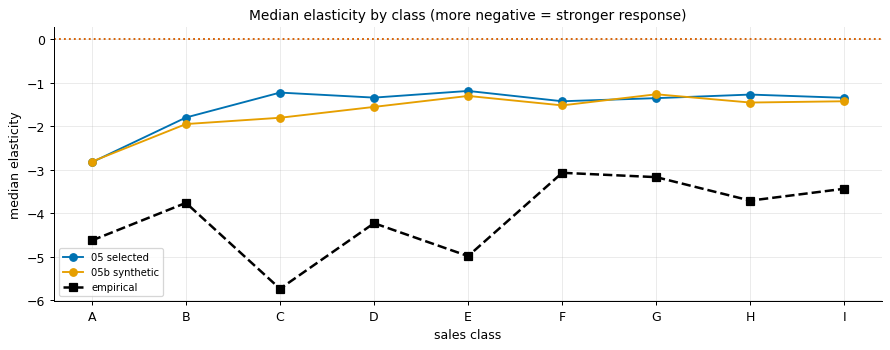

In [17]:
gplt.plot_elasticity_by_class(strength, info, empirical=empirical)

<!-- DRAFT: Graeme to edit -->
### Reading the result

* In F6, look first at the perverse (orange) share: if the cuts helped, it shrinks for 05b.
  Then at how much of each bar is elastic or stronger.
* In F7, a model line closer to the dashed empirical line is more realistic. Both models may
  sit well above it (weaker); the question is whether 05b closes some of the gap.

*Exact numbers vary with seed and hardware.*

<!-- DRAFT: Graeme to edit -->
## 8. Accuracy on the test window

05b's seed-mean forecast against 05's. The synthetic weeks sit only in the copies, so this
shows how far the planted cuts reach the forecasts for real series and real weeks.

The wins chart (F4) has three panels: the share of series 05b wins by class, by count and by
volume (0.5 is a draw); the spread of per-series gains; and one dot per series, head to head
(below the diagonal, 05b is better).

In [18]:
forecasts_b = gd.seed_forecasts(runs).rename(columns={"GFM_synthetic_mean": "GFM_synthetic"})
seed_cols = [c for c in forecasts_b.columns if c.startswith("GFM_synthetic_s")]
forecasts_a = gd.selected_forecasts(cfg_a)          # 05's forecasts, column GFM_selected
both = forecasts_a.merge(forecasts_b, on=["unique_id", "ds"])
rmsse = gd.per_series(gd.score(both, test, train))

seed_medians = rmsse[seed_cols].median()
accuracy = pd.Series({"05 median RMSSE": rmsse["GFM_selected"].median(),
                      "05b median RMSSE": rmsse["GFM_synthetic"].median(),
                      "05b seed spread (max - min)": seed_medians.max() - seed_medians.min(),
                      "noise floor (02)": noise_floor})
accuracy.round(4)

05 median RMSSE                0.5463
05b median RMSSE               0.5427
05b seed spread (max - min)    0.0038
noise floor (02)               0.0048
dtype: float64

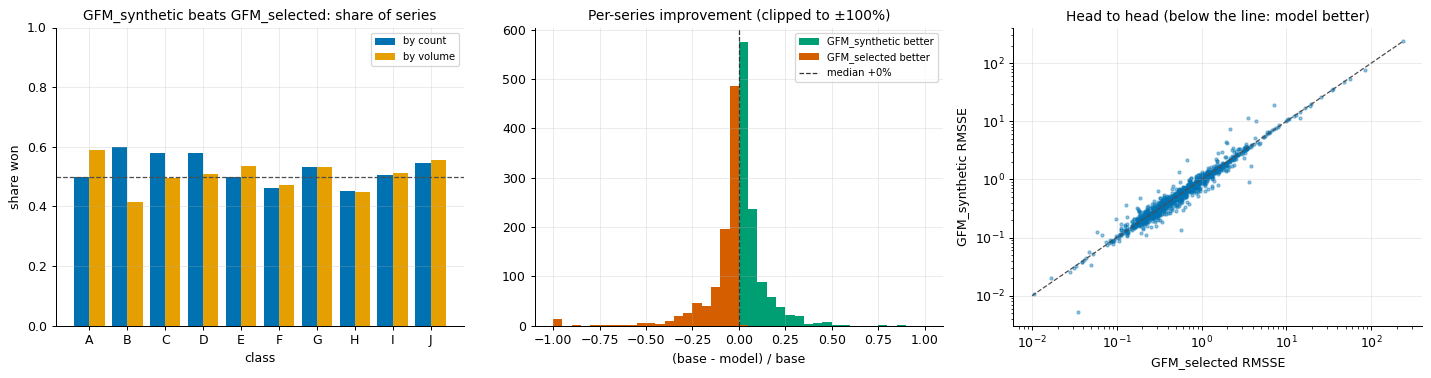

,win_share,win_share_volume,n
sale_class,,,
A,0.500,0.590,4.0
B,0.600,0.414,10.0
C,0.579,0.494,19.0
D,0.581,0.510,31.0
E,0.500,0.537,46.0
F,0.463,0.470,67.0
G,0.531,0.532,96.0
H,0.453,0.448,148.0
I,0.506,0.510,259.0


In [19]:
gplt.plot_wins(rmsse, info, model="GFM_synthetic", baseline="GFM_selected")

<!-- DRAFT: Graeme to edit -->
### Reading the result

* Lead with the median RMSSE: is 05b's within the noise floor of 05's (≈ 0.543 against
  ≈ 0.546)? Yes: the gap is smaller than the noise floor (≈ 0.005). The mean sits alongside
  on the board.
* A win share near 0.5 in every class means the cuts left ordinary forecasts alone. Losses
  bunched in one class point to where the made-up rule hurts.

*Exact numbers vary with seed and hardware.*

In [20]:
fit_seconds = gd.summaries(runs)["fit_seconds"].mean()
gd.save_forecasts(forecasts_b[["unique_id", "ds", "GFM_synthetic"]], "05b_synthetic")
gd.record(forecasts_b[["unique_id", "ds", "GFM_synthetic"]], test, train,
          lab=f"05b synthetic ({len(gd.SEEDS)}-seed mean)", fit_seconds=fit_seconds,
          notes="fit_seconds is per seed")
gd.median_board()

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
1,NBEATSx_B_cpi_mean,0.540,1.076,0.263,1999,04 price arms (3-seed mean),522.767
2,GFM_synthetic,0.543,1.077,0.260,1999,05b synthetic (3-seed mean),376.267
3,GFM_selected,0.546,1.067,0.257,1999,05 selected (3-seed mean),379.767
4,NBEATSx_C_cpi_over_mean,0.553,1.073,0.267,1999,04 price arms (3-seed mean),575.033
5,NBEATSx_A_features_mean,0.568,1.114,0.286,1999,04 price arms (3-seed mean),501.467
6,NBEATSx_recipe_mean,0.568,1.114,0.286,1999,01 recipe (3-seed mean),506.900
7,NBEATSx_tuned,0.568,1.114,0.286,1999,02 HPO round 1 (3-seed mean),537.767
8,LightGBM,0.569,1.161,0.295,1999,00 baselines (full panel),NaN
9,NBEATSx_cal_hier,0.647,1.170,0.328,1999,03 calendar and hierarchy (3-seed mean),527.233


<!-- DRAFT: Graeme to edit -->
## 9. What the synthetic model does on the example series (F12)

Forecasts at the planned price (base), and with every test-week price 20% lower and higher,
averaged over the three seeds. The lines should keep their order, with −20% on top; the gap
between them is the response, week by week.

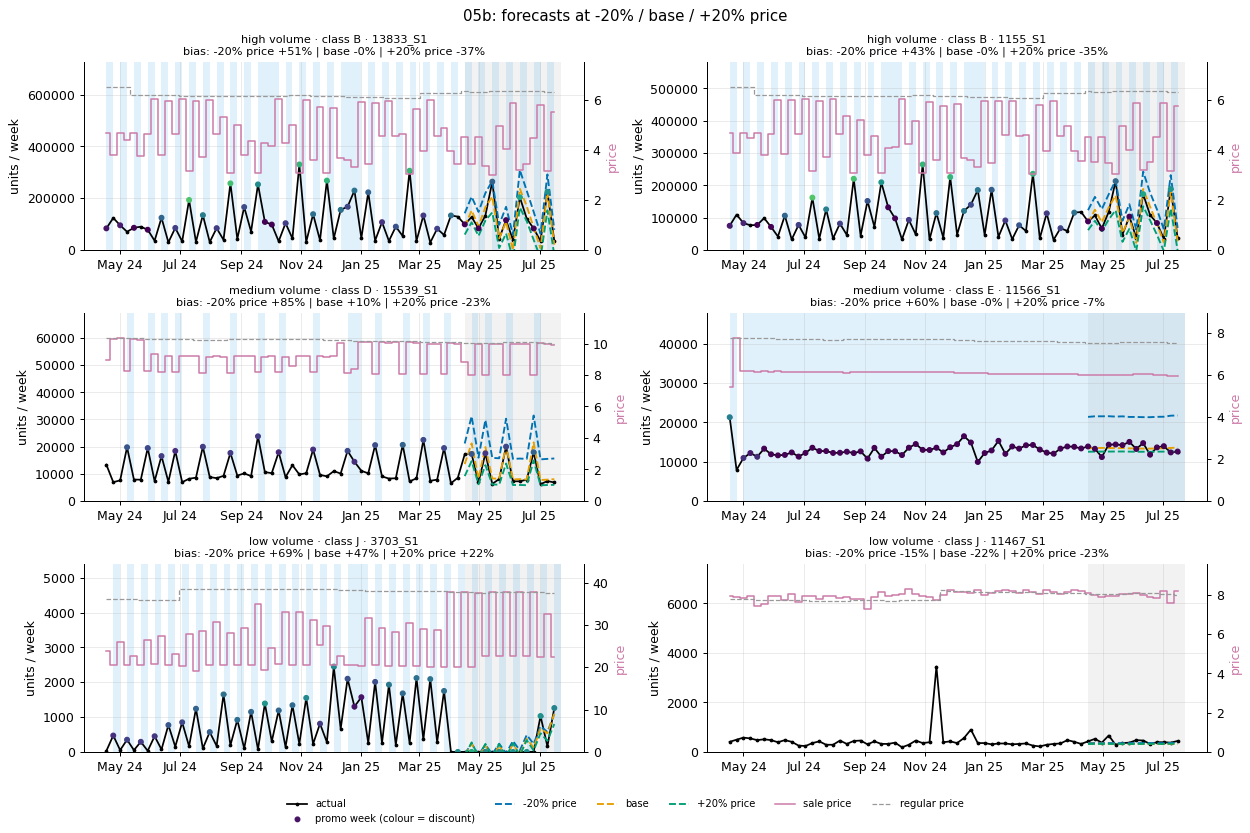

In [21]:
scenarios = seed_mean([r["scenarios"] for r in runs], ["unique_id", "ds"])
gplt.plot_series_price(panel, examples, scenarios, models=["-20% price", "base", "+20% price"],
                       title="05b: forecasts at -20% / base / +20% price")

<!-- DRAFT: Graeme to edit -->
## 10. The same checks on the test window (report only)

The three checks from section 2, now on the test window. They do not change `use`, which
was set on validation in section 3; they show whether the choice held. Remember that 05's
test numbers come from one saved seed.

In [22]:
test_checks = {
    "stronger response (median_e20 more negative)":
        reports.loc["05b synthetic", "median_e20"] < reports.loc["05 selected", "median_e20"],
    "more right-signed series (sustained probes)":
        right_sign_share(summary_b) > right_sign_share(summary_a),
    "accuracy within the noise floor":
        accuracy["05b median RMSSE"] - accuracy["05 median RMSSE"] <= noise_floor,
}
print(f"later notebooks use: {use} (chosen on validation)")
pd.DataFrame({"validation (chose)": checks, "test (report)": test_checks})

later notebooks use: 05 (chosen on validation)


,validation (chose),test (report)
stronger response (median_e20 more negative),True,True
more right-signed series (sustained probes),False,True
accuracy within the noise floor,True,True


In [23]:
gd.save_config("05b_synthetic", {
    **cfg_a,
    "oversample": cfg_b["oversample"],
    "oversample_added": oversample_added,
    "synthetic": cfg_b["synthetic"],
    "synthetic_seed": synthetic_seed,
    "max_steps": max_steps,
    "seeds": gd.SEEDS,
    "use": use,
    "rule": list(checks),
    "checks": {k: bool(v) for k, v in checks.items()},
    "checks_test": {k: bool(v) for k, v in test_checks.items()},
    "valid": valid_numbers.round(4).to_dict("index"),
    "elasticity": reports.round(4).to_dict("index"),
    "share_right_sign": {"05": right_sign_share(summary_a), "05b": right_sign_share(summary_b)},
    "echo": echo.round(4).reset_index().to_dict("records"),
    "median_rmsse": {"05": accuracy["05 median RMSSE"], "05b": accuracy["05b median RMSSE"]},
    "saved_model": "05b_synthetic",
    "forecasts": "05b_synthetic",
    "forecast_column": "GFM_synthetic",
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/05b_synthetic.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* The echo check shows whether the model *can* learn a response it is shown. We planted
  lifts close to the data's own ≈ −3.6. Would you plant the same lifts on a panel where the
  empirical elasticity was −0.5?
* Synthetic cuts sit in copies only. Did they change forecasts for real series in weeks with
  no price change?
* The rule needed all three checks. Which was hardest to pass, and why?

**Try it:** set `cuts_per_copy` to 4, or scale `gp.SYNTHETIC_LIFT` down by half, and rerun the
echo check. Does the measured lift follow the planted one?